[[Model]]
    Model(linear)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 7
    # data points      = 19
    # variables        = 2
    chi-square         = 425.833610
    reduced chi-square = 25.0490359
    Akaike info crit   = 63.0825844
    Bayesian info crit = 64.9714623
    R-squared          = 0.99634637
[[Variables]]
    slope:      0.46445032 +/- 0.00682138 (1.47%) (init = 1)
    intercept: -0.01309861 +/- 4.0926e-04 (3.12%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(slope, intercept) = -0.9598

chi2 = 425.83361036924714
vrijheidsgraden = 17
gereduceerde chi2 = 25.04903590407336


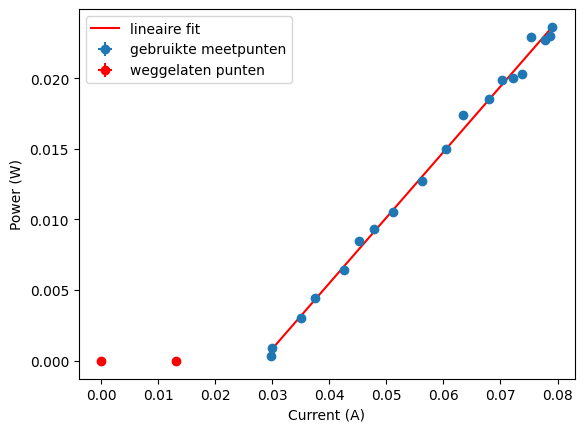

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from lmfit import models
from scipy import stats

Current_A = [
    0.02E-3, 78.63E-3, 51.09E-3, 42.51E-3, 29.72E-3,
    56.23E-3, 13.04E-3, 30E-3, 35.09E-3, 37.5E-3,
    45.12E-3, 47.87E-3, 63.47E-3, 67.98E-3,
    70.32E-3, 60.46E-3, 75.31E-3, 72.26E-3,
    73.76E-3, 77.75E-3, 79.07E-3
]

Power_W = [
    0, 23E-3, 10.5E-3, 6.4E-3, 0.3E-3,
    12.7E-3, 0, 0.9E-3, 3E-3, 4.4E-3,
    8.5E-3, 9.3E-3, 17.4E-3, 18.5E-3,
    19.9E-3, 15E-3, 22.9E-3, 20E-3,
    20.3E-3, 22.7E-3, 23.6E-3
]

#foutmarges
Current_error_A = 0.005E-3
Power_error_W = 0.1E-3


#de twee nulpunten weg.
Current_selection_A = Current_A.copy()
Power_selection_W = Power_W.copy()

Current_masked_A = []
Power_masked_W = []

# eerste punt weghalen
Current_masked_A.append(Current_selection_A.pop(0))
Power_masked_W.append(Power_selection_W.pop(0))

# tweede nulpunt weghalen
Current_masked_A.append(Current_selection_A.pop(5))
Power_masked_W.append(Power_selection_W.pop(5))

Current_selection_err_A = [Current_error_A] * len(Current_selection_A)
Power_selection_err_W = [Power_error_W] * len(Power_selection_W)

Current_masked_err_A = [Current_error_A] * len(Current_masked_A)
Power_masked_err_W = [Power_error_W] * len(Power_masked_W)


mod_linear = models.LinearModel()


y_err_array = np.array(Power_selection_err_W)
y_inv_err = 1 / y_err_array

fit_result = mod_linear.fit(
    Power_selection_W,
    x=Current_selection_A,
    weights=y_inv_err
)

print(fit_result.fit_report())



chi_square = fit_result.chisqr
degrees_of_freedom = fit_result.nfree
red_chi_square = fit_result.redchi




print()
print("chi2 =", chi_square)
print("vrijheidsgraden =", degrees_of_freedom)
print("gereduceerde chi2 =", red_chi_square)



plt.figure()


plt.errorbar(
    Current_selection_A,
    Power_selection_W,
    xerr=Current_selection_err_A,
    yerr=Power_selection_err_W,
    fmt='o',
    label='gebruikte meetpunten')

plt.errorbar(
    Current_masked_A,
    Power_masked_W,
    xerr=Current_masked_err_A,
    yerr=Power_masked_err_W,
    fmt='ro',
    label='weggelaten punten')

Current_fit_A = np.linspace(min(Current_selection_A), max(Current_selection_A), 100)
Power_fit_W = fit_result.eval(x=Current_fit_A)

plt.plot(
    Current_fit_A,
    Power_fit_W,
    'r-',
    label='lineaire fit')

plt.xlabel('Current (A)')
plt.ylabel('Power (W)')
plt.legend(loc='best')
plt.show()